# Member 3: Class Imbalance Handling for Neural Network (PyTorch MLP)

- **Objective:** Compare `BCEWithLogitsLoss(pos_weight=...)` and `BinaryFocalLoss(alpha, gamma)` under a fixed 4-layer `FraudMLP` architecture on `train_folds.csv` (65 leak-free features via `nn_data_pipeline.py`).
- **Primary Metric:** Out-Of-Fold **AUPRC** (alongside ROC-AUC, `F1 @ 0.50`, and optimal threshold `Best F1`).
- **Outputs:** `nn_imbalance_pipeline.py` (via `%%writefile`) and `nn_imbalance_config.json`.

## 1. Shared Module Export (`nn_imbalance_pipeline.py`) & Data Setup

In [1]:
%%writefile nn_imbalance_pipeline.py
"""Shared PyTorch MLP and class-imbalance loss experimentation pipeline for Member 3."""

import copy
import math
import random
from typing import Any

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

from data_pipeline.nn_data_pipeline import evaluate_auprc


def set_seed(seed: int = 42) -> None:
    """Set deterministic seeds for Python, NumPy, and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


class FraudMLP(nn.Module):
    """Controlled 4-layer tabular MLP: Linear -> BatchNorm1d -> ReLU -> Dropout."""

    def __init__(
        self,
        in_features: int,
        hidden_dims: tuple[int, ...] = (256, 128, 64, 32),
        dropouts: tuple[float, ...] = (0.30, 0.25, 0.20, 0.10),
        init_pos_prob: float | None = None,
    ) -> None:
        super().__init__()
        if len(hidden_dims) != len(dropouts):
            raise ValueError("hidden_dims and dropouts must have equal length.")

        layers: list[nn.Module] = []
        prev_dim = in_features
        for h_dim, drop in zip(hidden_dims, dropouts):
            lin = nn.Linear(prev_dim, h_dim)
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")
            nn.init.zeros_(lin.bias)
            layers.extend([
                lin,
                nn.BatchNorm1d(h_dim),
                nn.ReLU(),
                nn.Dropout(p=drop),
            ])
            prev_dim = h_dim

        self.backbone = nn.Sequential(*layers)
        self.head = nn.Linear(prev_dim, 1)
        nn.init.xavier_normal_(self.head.weight)
        if init_pos_prob is not None and 0.0 < init_pos_prob < 1.0:
            nn.init.constant_(self.head.bias, math.log(init_pos_prob / (1.0 - init_pos_prob)))
        else:
            nn.init.zeros_(self.head.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.backbone(x)).squeeze(-1)


class BinaryFocalLoss(nn.Module):
    """Logit-based Binary Focal Loss for imbalanced binary classification."""

    def __init__(self, alpha: float | None = None, gamma: float = 2.0) -> None:
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        p_t = torch.exp(-bce)
        loss = ((1.0 - p_t) ** self.gamma) * bce
        if self.alpha is not None:
            alpha_t = self.alpha * targets + (1.0 - self.alpha) * (1.0 - targets)
            loss = alpha_t * loss
        return loss.mean()


def make_loss(
    loss_type: str,
    y_train: np.ndarray,
    device: torch.device,
    pos_weight: float | str | None = None,
    alpha: float | None = None,
    gamma: float = 2.0,
) -> tuple[nn.Module, float | None, float]:
    """Build loss function strictly from training fold targets (zero data leakage)."""
    n_pos = float(np.sum(y_train == 1))
    n_neg = float(np.sum(y_train == 0))
    ir = n_neg / max(n_pos, 1.0)
    prior = n_pos / max(n_pos + n_neg, 1.0)

    if loss_type == "bce":
        if pos_weight is None or pos_weight == 1.0:
            eff_pw = 1.0
            return nn.BCEWithLogitsLoss(), prior, eff_pw
        if pos_weight == "sqrt":
            eff_pw = math.sqrt(ir)
        elif pos_weight == "balanced":
            eff_pw = ir
        else:
            eff_pw = float(pos_weight)
        pw_tensor = torch.tensor([eff_pw], dtype=torch.float32, device=device)
        return nn.BCEWithLogitsLoss(pos_weight=pw_tensor), None, float(eff_pw)

    if loss_type == "focal":
        return BinaryFocalLoss(alpha=alpha, gamma=gamma), prior, 1.0

    raise ValueError(f"Unsupported loss_type: {loss_type}")


@torch.no_grad()
def predict_proba_tensor(
    model: nn.Module,
    X_tensor: torch.Tensor,
    batch_size: int = 16384,
) -> np.ndarray:
    """Compute sigmoid probabilities in batches."""
    model.eval()
    n = X_tensor.shape[0]
    preds = np.empty(n, dtype=np.float64)
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        logits = model(X_tensor[start:end])
        preds[start:end] = torch.sigmoid(logits).detach().cpu().numpy()
    return preds


def train_mlp_fold(
    fold_data: dict[str, Any],
    loss_cfg: dict[str, Any],
    seed: int = 42,
    hidden_dims: tuple[int, ...] = (256, 128, 64, 32),
    dropouts: tuple[float, ...] = (0.30, 0.25, 0.20, 0.10),
    lr: float = 2e-3,
    weight_decay: float = 1e-4,
    batch_size: int = 4096,
    max_epochs: int = 22,
    patience: int = 5,
    clip_val: float = 20.0,
    verbose: bool = False,
) -> tuple[np.ndarray, float, dict[str, Any]]:
    """Train FraudMLP on one fold with deterministic outlier clipping and AUPRC early stopping."""
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    X_tr = np.clip(fold_data["X_train"], -clip_val, clip_val).astype(np.float32)
    X_va = np.clip(fold_data["X_val"], -clip_val, clip_val).astype(np.float32)
    y_tr = fold_data["y_train"].astype(np.float32)
    y_va = fold_data["y_val"].astype(np.int64)

    criterion, init_prior, eff_pw = make_loss(
        loss_type=loss_cfg["loss_type"],
        y_train=fold_data["y_train"],
        device=device,
        pos_weight=loss_cfg.get("pos_weight_mode"),
        alpha=loss_cfg.get("alpha"),
        gamma=loss_cfg.get("gamma", 2.0),
    )

    model = FraudMLP(
        in_features=X_tr.shape[1],
        hidden_dims=hidden_dims,
        dropouts=dropouts,
        init_pos_prob=init_prior,
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )

    X_tr_t = torch.from_numpy(X_tr).to(device)
    y_tr_t = torch.from_numpy(y_tr).to(device)
    X_va_t = torch.from_numpy(X_va).to(device)

    n_train = X_tr_t.shape[0]
    best_auprc = -1.0
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    no_improve = 0
    history: dict[str, Any] = {"train_loss": [], "val_auprc": [], "effective_pos_weight": eff_pw}

    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(n_train, device=device)
        epoch_loss = 0.0
        seen = 0

        for start in range(0, n_train, batch_size):
            end = min(start + batch_size, n_train)
            if end - start < 2:
                continue
            idx = perm[start:end]
            optimizer.zero_grad(set_to_none=True)
            logits = model(X_tr_t[idx])
            loss = criterion(logits, y_tr_t[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            bs = end - start
            epoch_loss += float(loss.item()) * bs
            seen += bs

        avg_loss = epoch_loss / max(seen, 1)
        val_probs = predict_proba_tensor(model, X_va_t)
        val_auprc = evaluate_auprc(y_va, val_probs)
        scheduler.step(val_auprc)

        history["train_loss"].append(avg_loss)
        history["val_auprc"].append(val_auprc)

        if val_auprc > best_auprc + 1e-6:
            best_auprc = val_auprc
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if verbose and (epoch == 1 or epoch % 5 == 0 or no_improve == 0):
            cur_lr = optimizer.param_groups[0]["lr"]
            print(
                f"  Epoch {epoch:02d}/{max_epochs} | loss={avg_loss:.5f} "
                f"| val_auprc={val_auprc:.5f} | lr={cur_lr:.2e}"
            )

        if no_improve >= patience:
            break

    model.load_state_dict(best_state)
    val_probs = predict_proba_tensor(model, X_va_t)
    history["best_epoch"] = best_epoch
    return val_probs, float(best_auprc), history


def evaluate_binary_metrics(y_true: np.ndarray, y_proba: np.ndarray) -> dict[str, Any]:
    """Compute AUPRC, ROC-AUC, F1@0.50, optimal F1 threshold, and confusion counts."""
    y_true_arr = np.asarray(y_true, dtype=np.int64)
    y_prob_arr = np.asarray(y_proba, dtype=np.float64)

    auprc = evaluate_auprc(y_true_arr, y_prob_arr)
    roc_auc = float(roc_auc_score(y_true_arr, y_prob_arr))

    prec, rec, thresholds = precision_recall_curve(y_true_arr, y_prob_arr)
    f1_scores = np.divide(
        2.0 * prec * rec,
        prec + rec,
        out=np.zeros_like(prec),
        where=(prec + rec) != 0,
    )
    best_idx = int(np.argmax(f1_scores))
    best_th = float(thresholds[best_idx]) if best_idx < len(thresholds) else 0.5
    best_f1 = float(f1_scores[best_idx])

    y_pred_best = (y_prob_arr >= best_th).astype(np.int64)
    f1_default = float(f1_score(y_true_arr, (y_prob_arr >= 0.5).astype(np.int64), zero_division=0))
    tn, fp, fn, tp = confusion_matrix(y_true_arr, y_pred_best).ravel()

    return {
        "auprc": auprc,
        "roc_auc": roc_auc,
        "f1_at_050": f1_default,
        "best_f1": best_f1,
        "best_threshold": best_th,
        "precision_at_best_f1": float(precision_score(y_true_arr, y_pred_best, zero_division=0)),
        "recall_at_best_f1": float(recall_score(y_true_arr, y_pred_best, zero_division=0)),
        "tp": int(tp),
        "fp": int(fp),
        "tn": int(tn),
        "fn": int(fn),
    }

Overwriting nn_imbalance_pipeline.py


In [2]:
import json
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import precision_recall_curve

from data_pipeline.nn_data_pipeline import N_SPLITS, ensure_train_folds, evaluate_auprc, get_nn_fold_data, iter_nn_folds
from nn.nn_imbalance_pipeline import evaluate_binary_metrics, train_mlp_fold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"PyTorch {torch.__version__} | CUDA={torch.cuda.is_available()} | Device: {device_name}")

train_folds = ensure_train_folds("train_folds.csv", "train.csv")
y_all = train_folds["is_fraud"].to_numpy(dtype=np.int64)
n_neg = int((y_all == 0).sum())
n_pos = int((y_all == 1).sum())
ir = n_neg / n_pos
print(f"Train rows: {len(train_folds):,} | Non-Fraud: {n_neg:,} | Fraud: {n_pos:,} ({n_pos/len(y_all)*100:.3f}%)")
print(f"Imbalance Ratio (IR): {ir:.2f} | sqrt(IR): {math.sqrt(ir):.2f}")

fold0 = get_nn_fold_data(0, "train_folds.csv", "test.csv")
print(f"Fold 0 -> X_train: {fold0['X_train'].shape}, X_val: {fold0['X_val'].shape}, NaNs: {np.isnan(fold0['X_train']).any()}")

PyTorch 2.6.0+cu124 | CUDA=True | Device: NVIDIA GeForce RTX 2050


Train rows: 699,960 | Non-Fraud: 688,271 | Fraud: 11,689 (1.670%)
Imbalance Ratio (IR): 58.88 | sqrt(IR): 7.67


Fold 0 -> X_train: (559968, 65), X_val: (139992, 65), NaNs: False


## 2. Stage 1: Fold 0 Screening Across 9 Loss Configurations
Evaluate `BCEWithLogitsLoss(pos_weight=...)` (5 settings) and `BinaryFocalLoss(alpha, gamma)` (4 settings) on Fold 0 under identical architecture and optimizer settings.

In [3]:
EXPERIMENTS = [
    {"exp_id": "EXP-NN-1A", "category": "Baseline", "strategy": "BCEWithLogits (pos_weight=1.0, Unweighted)", "loss_type": "bce", "pos_weight_mode": 1.0, "alpha": None, "gamma": None},
    {"exp_id": "EXP-NN-1B", "category": "BCE_Weighted", "strategy": "BCEWithLogits (pos_weight=3.0, Mild)", "loss_type": "bce", "pos_weight_mode": 3.0, "alpha": None, "gamma": None},
    {"exp_id": "EXP-NN-1C", "category": "BCE_Weighted", "strategy": "BCEWithLogits (pos_weight=sqrt(IR))", "loss_type": "bce", "pos_weight_mode": "sqrt", "alpha": None, "gamma": None},
    {"exp_id": "EXP-NN-1D", "category": "BCE_Weighted", "strategy": "BCEWithLogits (pos_weight=15.0)", "loss_type": "bce", "pos_weight_mode": 15.0, "alpha": None, "gamma": None},
    {"exp_id": "EXP-NN-1E", "category": "BCE_Weighted", "strategy": "BCEWithLogits (pos_weight=IR, Full Balanced)", "loss_type": "bce", "pos_weight_mode": "balanced", "alpha": None, "gamma": None},
    {"exp_id": "EXP-NN-2A", "category": "Focal_Loss", "strategy": "Focal Loss (gamma=1.0, alpha=None)", "loss_type": "focal", "pos_weight_mode": None, "alpha": None, "gamma": 1.0},
    {"exp_id": "EXP-NN-2B", "category": "Focal_Loss", "strategy": "Focal Loss (gamma=2.0, alpha=None)", "loss_type": "focal", "pos_weight_mode": None, "alpha": None, "gamma": 2.0},
    {"exp_id": "EXP-NN-2C", "category": "Focal_Loss", "strategy": "Focal Loss (gamma=2.0, alpha=0.25)", "loss_type": "focal", "pos_weight_mode": None, "alpha": 0.25, "gamma": 2.0},
    {"exp_id": "EXP-NN-2D", "category": "Focal_Loss", "strategy": "Focal Loss (gamma=2.0, alpha=0.75)", "loss_type": "focal", "pos_weight_mode": None, "alpha": 0.75, "gamma": 2.0},
]

stage1_rows = []
stage1_histories = {}
stage1_probs = {}

for cfg in EXPERIMENTS:
    t0 = time.time()
    val_p, best_ap, hist = train_mlp_fold(
        fold0, cfg, seed=42, lr=2e-3, batch_size=4096, max_epochs=22, patience=5, verbose=False
    )
    met = evaluate_binary_metrics(fold0["y_val"], val_p)
    elapsed = round(time.time() - t0, 1)
    stage1_histories[cfg["exp_id"]] = hist
    stage1_probs[cfg["exp_id"]] = val_p
    stage1_rows.append({
        "Exp_ID": cfg["exp_id"],
        "Category": cfg["category"],
        "Strategy": cfg["strategy"],
        "Val_AUPRC": met["auprc"],
        "Val_ROC_AUC": met["roc_auc"],
        "F1_at_0.50": met["f1_at_050"],
        "Best_F1": met["best_f1"],
        "Best_Threshold": met["best_threshold"],
        "Best_Epoch": hist["best_epoch"],
        "Time_Sec": elapsed,
    })
    print(
        f"[{cfg['exp_id']}] {cfg['strategy']:44s} | AUPRC={met['auprc']:.5f} "
        f"| BestF1={met['best_f1']:.4f} (@th={met['best_threshold']:.3f}) | F1@0.5={met['f1_at_050']:.4f} | {elapsed:.1f}s"
    )

stage1_df = pd.DataFrame(stage1_rows).sort_values("Val_AUPRC", ascending=False).reset_index(drop=True)
display(stage1_df.round(5))

[EXP-NN-1A] BCEWithLogits (pos_weight=1.0, Unweighted)   | AUPRC=0.48336 | BestF1=0.4803 (@th=0.143) | F1@0.5=0.3223 | 13.5s


[EXP-NN-1B] BCEWithLogits (pos_weight=3.0, Mild)         | AUPRC=0.48296 | BestF1=0.4793 (@th=0.520) | F1@0.5=0.4762 | 31.2s


[EXP-NN-1C] BCEWithLogits (pos_weight=sqrt(IR))          | AUPRC=0.48267 | BestF1=0.4804 (@th=0.626) | F1@0.5=0.4611 | 40.9s


[EXP-NN-1D] BCEWithLogits (pos_weight=15.0)              | AUPRC=0.48224 | BestF1=0.4805 (@th=0.732) | F1@0.5=0.3627 | 26.6s


[EXP-NN-1E] BCEWithLogits (pos_weight=IR, Full Balanced) | AUPRC=0.48190 | BestF1=0.4837 (@th=0.947) | F1@0.5=0.1846 | 43.8s


[EXP-NN-2A] Focal Loss (gamma=1.0, alpha=None)           | AUPRC=0.48384 | BestF1=0.4833 (@th=0.266) | F1@0.5=0.2860 | 36.6s


[EXP-NN-2B] Focal Loss (gamma=2.0, alpha=None)           | AUPRC=0.48347 | BestF1=0.4840 (@th=0.313) | F1@0.5=0.2277 | 23.1s


[EXP-NN-2C] Focal Loss (gamma=2.0, alpha=0.25)           | AUPRC=0.48407 | BestF1=0.4828 (@th=0.234) | F1@0.5=0.0828 | 68.2s


[EXP-NN-2D] Focal Loss (gamma=2.0, alpha=0.75)           | AUPRC=0.48303 | BestF1=0.4833 (@th=0.422) | F1@0.5=0.4271 | 44.7s


,Exp_ID,Category,Strategy,Val_AUPRC,Val_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Best_Epoch,Time_Sec
0,EXP-NN-2C,Focal_Loss,"Focal Loss (gamma=2.0, alpha=0.25)",0.48407,0.94134,0.08279,0.48276,0.23390,17,68.2
1,EXP-NN-2A,Focal_Loss,"Focal Loss (gamma=1.0, alpha=None)",0.48384,0.94157,0.28602,0.48329,0.26561,8,36.6
2,EXP-NN-2B,Focal_Loss,"Focal Loss (gamma=2.0, alpha=None)",0.48347,0.94217,0.22773,0.48403,0.31287,8,23.1
3,EXP-NN-1A,Baseline,"BCEWithLogits (pos_weight=1.0, Unweighted)",0.48336,0.94142,0.32227,0.48031,0.14265,8,13.5
4,EXP-NN-2D,Focal_Loss,"Focal Loss (gamma=2.0, alpha=0.75)",0.48303,0.94155,0.42711,0.48328,0.42197,8,44.7
5,EXP-NN-1B,BCE_Weighted,"BCEWithLogits (pos_weight=3.0, Mild)",0.48296,0.94039,0.47623,0.47933,0.52023,9,31.2
6,EXP-NN-1C,BCE_Weighted,BCEWithLogits (pos_weight=sqrt(IR)),0.48267,0.94004,0.46109,0.48044,0.62604,12,40.9
7,EXP-NN-1D,BCE_Weighted,BCEWithLogits (pos_weight=15.0),0.48224,0.94085,0.36269,0.48049,0.73188,8,26.6
8,EXP-NN-1E,BCE_Weighted,"BCEWithLogits (pos_weight=IR, Full Balanced)",0.48190,0.93900,0.18458,0.48365,0.94729,20,43.8


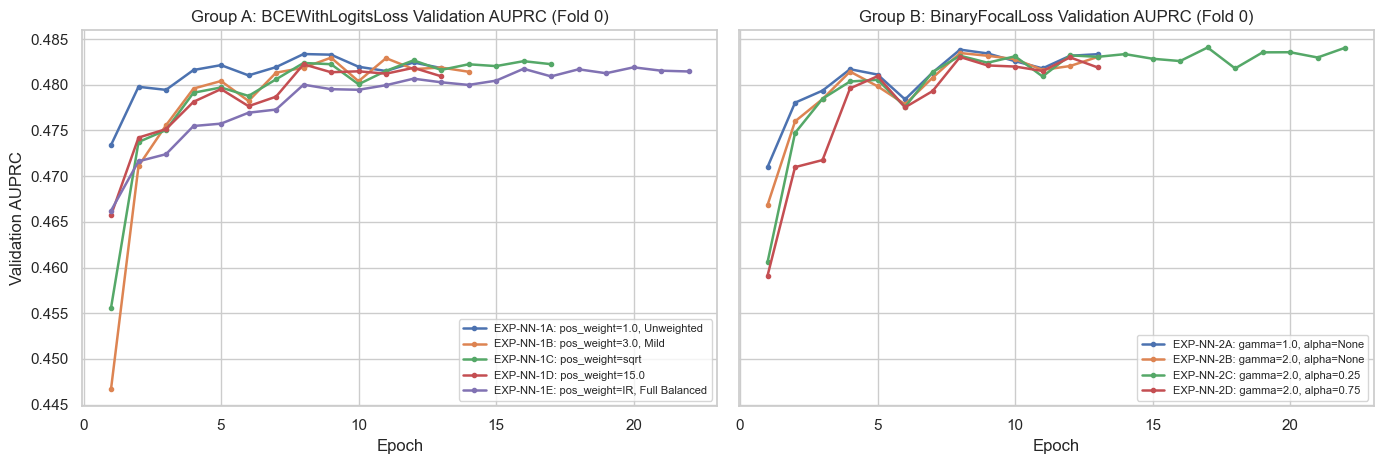

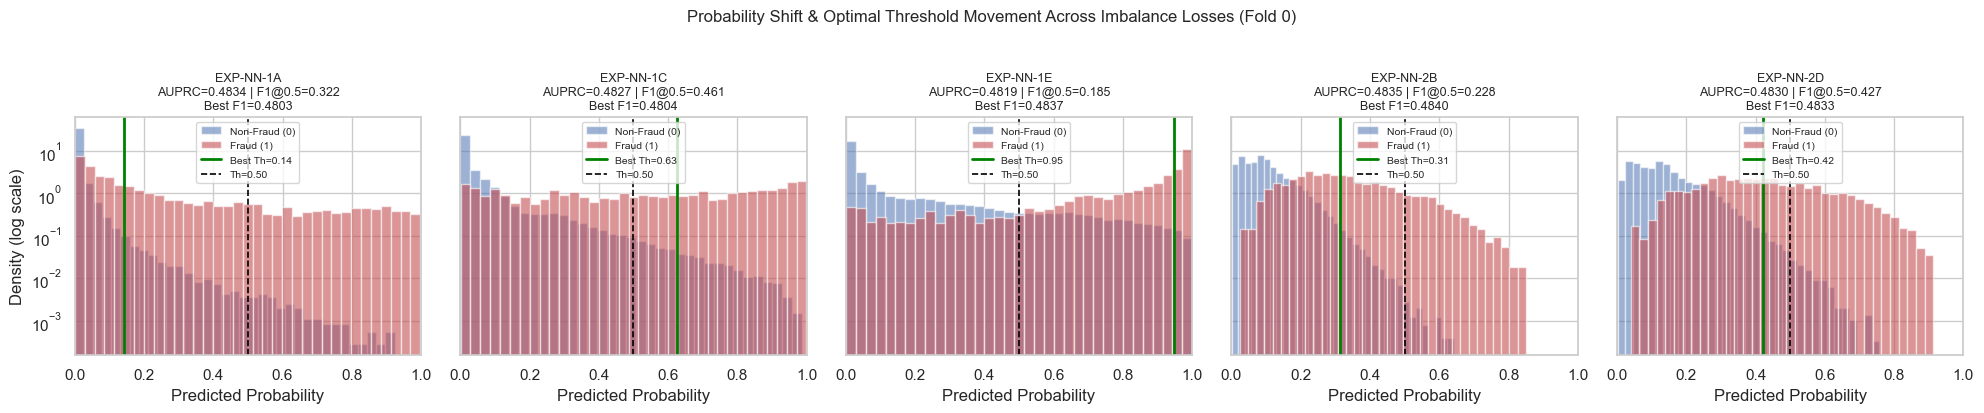

In [4]:
# Figure 1: Fold 0 Learning Curves (BCE vs Focal)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for cfg in EXPERIMENTS:
    eid = cfg["exp_id"]
    hist = stage1_histories[eid]
    epochs = range(1, len(hist["val_auprc"]) + 1)
    ax = axes[0] if cfg["loss_type"] == "bce" else axes[1]
    ax.plot(epochs, hist["val_auprc"], marker=".", lw=1.8, label=f"{eid}: {cfg['strategy'].split('(')[1].rstrip(')')}")

axes[0].set_title("Group A: BCEWithLogitsLoss Validation AUPRC (Fold 0)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation AUPRC")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].set_title("Group B: BinaryFocalLoss Validation AUPRC (Fold 0)")
axes[1].set_xlabel("Epoch")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

# Figure 2: Probability Shift & Optimal Threshold Shift
rep_ids = ["EXP-NN-1A", "EXP-NN-1C", "EXP-NN-1E", "EXP-NN-2B", "EXP-NN-2D"]
y_f0 = fold0["y_val"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.0), sharey=True)
for ax, eid in zip(axes, rep_ids):
    probs = stage1_probs[eid]
    row = stage1_df[stage1_df["Exp_ID"] == eid].iloc[0]
    ax.hist(probs[y_f0 == 0], bins=35, density=True, alpha=0.55, color="#4c72b0", label="Non-Fraud (0)")
    ax.hist(probs[y_f0 == 1], bins=35, density=True, alpha=0.60, color="#c44e52", label="Fraud (1)")
    ax.axvline(row["Best_Threshold"], color="green", lw=2.0, label=f"Best Th={row['Best_Threshold']:.2f}")
    ax.axvline(0.50, color="black", linestyle="--", lw=1.2, label="Th=0.50")
    ax.set_yscale("log")
    ax.set_xlim(0, 1)
    ax.set_title(f"{eid}\nAUPRC={row['Val_AUPRC']:.4f} | F1@0.5={row['F1_at_0.50']:.3f}\nBest F1={row['Best_F1']:.4f}", fontsize=9)
    ax.set_xlabel("Predicted Probability")
    ax.legend(fontsize=7.5, loc="upper center")
axes[0].set_ylabel("Density (log scale)")
plt.suptitle("Probability Shift & Optimal Threshold Movement Across Imbalance Losses (Fold 0)", y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

## 3. Stage 2: Full 5-Fold Stratified CV Confirmation
Confirm the Stage 1 baseline (`EXP-NN-1A`), top weighted BCE candidate, and top Focal Loss candidate across all 5 folds (`699,960` OOF predictions).

In [5]:
best_bce_id = stage1_df[stage1_df["Category"] == "BCE_Weighted"].iloc[0]["Exp_ID"]
best_focal_id = stage1_df[stage1_df["Category"] == "Focal_Loss"].iloc[0]["Exp_ID"]
finalist_ids = []
for eid in ["EXP-NN-1A", best_bce_id, best_focal_id]:
    if eid not in finalist_ids:
        finalist_ids.append(eid)

exp_lookup = {c["exp_id"]: c for c in EXPERIMENTS}
finalists = [exp_lookup[eid] for eid in finalist_ids]
print("Stage 2 Finalists:", [f"{c['exp_id']} ({c['strategy']})" for c in finalists])

oof_store = {c["exp_id"]: np.zeros(len(train_folds), dtype=np.float64) for c in finalists}
fold_ap_store = {c["exp_id"]: [] for c in finalists}
time_store = {c["exp_id"]: 0.0 for c in finalists}

for fold_k, fold_data in iter_nn_folds("train_folds.csv", "test.csv"):
    val_ids = fold_data["val_ids"]
    for cfg in finalists:
        eid = cfg["exp_id"]
        t0 = time.time()
        val_p, best_ap, hist = train_mlp_fold(
            fold_data, cfg, seed=42 + fold_k, lr=2e-3, batch_size=4096, max_epochs=22, patience=5, verbose=False
        )
        oof_store[eid][val_ids] = val_p
        fold_ap_store[eid].append(best_ap)
        time_store[eid] += time.time() - t0
        print(f"  Fold {fold_k} | {eid} | val_auprc={best_ap:.5f} (epoch={hist['best_epoch']})")

stage2_rows = []
baseline_oof_ap = evaluate_auprc(y_all, oof_store["EXP-NN-1A"])
for cfg in finalists:
    eid = cfg["exp_id"]
    met = evaluate_binary_metrics(y_all, oof_store[eid])
    f_aps = fold_ap_store[eid]
    stage2_rows.append({
        "Exp_ID": eid,
        "Strategy": cfg["strategy"],
        "OOF_AUPRC": met["auprc"],
        "Mean_Fold_AUPRC": float(np.mean(f_aps)),
        "Std_Fold_AUPRC": float(np.std(f_aps)),
        "Delta_vs_Unweighted": met["auprc"] - baseline_oof_ap,
        "OOF_ROC_AUC": met["roc_auc"],
        "F1_at_0.50": met["f1_at_050"],
        "Best_F1": met["best_f1"],
        "Best_Threshold": met["best_threshold"],
        "Train_Time_Sec": round(time_store[eid], 1),
    })

stage2_df = pd.DataFrame(stage2_rows).sort_values("OOF_AUPRC", ascending=False).reset_index(drop=True)
display(stage2_df.round(5))

Stage 2 Finalists: ['EXP-NN-1A (BCEWithLogits (pos_weight=1.0, Unweighted))', 'EXP-NN-1B (BCEWithLogits (pos_weight=3.0, Mild))', 'EXP-NN-2C (Focal Loss (gamma=2.0, alpha=0.25))']


  Fold 0 | EXP-NN-1A | val_auprc=0.48336 (epoch=8)


  Fold 0 | EXP-NN-1B | val_auprc=0.48296 (epoch=9)


  Fold 0 | EXP-NN-2C | val_auprc=0.48407 (epoch=17)


  Fold 1 | EXP-NN-1A | val_auprc=0.49955 (epoch=8)


  Fold 1 | EXP-NN-1B | val_auprc=0.49827 (epoch=9)


... (7 outputs left out)

  Fold 4 | EXP-NN-1A | val_auprc=0.48410 (epoch=12)


  Fold 4 | EXP-NN-1B | val_auprc=0.48180 (epoch=20)


  Fold 4 | EXP-NN-2C | val_auprc=0.48330 (epoch=12)


,Exp_ID,Strategy,OOF_AUPRC,Mean_Fold_AUPRC,Std_Fold_AUPRC,Delta_vs_Unweighted,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Train_Time_Sec
0,EXP-NN-1A,"BCEWithLogits (pos_weight=1.0, Unweighted)",0.49036,0.49376,0.00976,0.00000,0.94172,0.36520,0.48474,0.17306,148.4
1,EXP-NN-2C,"Focal Loss (gamma=2.0, alpha=0.25)",0.48940,0.49329,0.00958,-0.00096,0.94189,0.13116,0.48606,0.25199,196.5
2,EXP-NN-1B,"BCEWithLogits (pos_weight=3.0, Mild)",0.48830,0.49278,0.01004,-0.00206,0.94090,0.48254,0.48613,0.45168,194.8


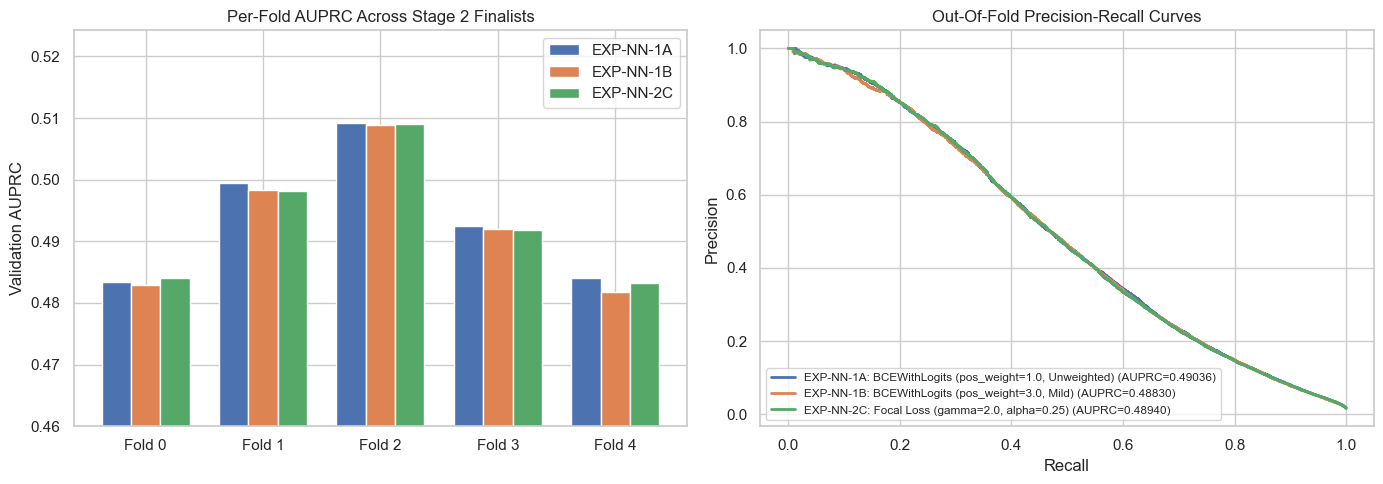

In [6]:
# Figure 3: 5-Fold Comparison & Overlaid OOF Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(N_SPLITS)
width = 0.25
for i, cfg in enumerate(finalists):
    eid = cfg["exp_id"]
    axes[0].bar(x + (i - 1) * width, fold_ap_store[eid], width=width, label=f"{eid}")
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"Fold {k}" for k in range(N_SPLITS)])
axes[0].set_ylabel("Validation AUPRC")
axes[0].set_title("Per-Fold AUPRC Across Stage 2 Finalists")
axes[0].set_ylim(0.46, max(max(v) for v in fold_ap_store.values()) + 0.015)
axes[0].legend()

for cfg in finalists:
    eid = cfg["exp_id"]
    pr, rc, _ = precision_recall_curve(y_all, oof_store[eid])
    ap = evaluate_auprc(y_all, oof_store[eid])
    axes[1].plot(rc, pr, lw=2, label=f"{eid}: {cfg['strategy']} (AUPRC={ap:.5f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Out-Of-Fold Precision-Recall Curves")
axes[1].legend(fontsize=8.5, loc="lower left")

plt.tight_layout()
plt.show()

## 4. Export Winning Imbalance Config (`nn_imbalance_config.json`)

In [7]:
winner_row = stage2_df.iloc[0]
winner_eid = winner_row["Exp_ID"]
winner_cfg = exp_lookup[winner_eid]

config_out = {
    "exp_id": winner_eid,
    "strategy": winner_cfg["strategy"],
    "loss_type": winner_cfg["loss_type"],
    "pos_weight_mode": winner_cfg["pos_weight_mode"],
    "alpha": winner_cfg["alpha"],
    "gamma": winner_cfg["gamma"],
    "clip_val": 20.0,
    "hidden_dims": [256, 128, 64, 32],
    "dropouts": [0.30, 0.25, 0.20, 0.10],
    "oof_auprc": float(winner_row["OOF_AUPRC"]),
    "mean_fold_auprc": float(winner_row["Mean_Fold_AUPRC"]),
    "std_fold_auprc": float(winner_row["Std_Fold_AUPRC"]),
    "oof_roc_auc": float(winner_row["OOF_ROC_AUC"]),
    "f1_at_0.50": float(winner_row["F1_at_0.50"]),
    "best_f1": float(winner_row["Best_F1"]),
    "best_threshold": float(winner_row["Best_Threshold"]),
    "delta_vs_unweighted": float(winner_row["Delta_vs_Unweighted"]),
    "fold_auprcs": [float(v) for v in fold_ap_store[winner_eid]],
    "stage2_comparison": stage2_df.to_dict(orient="records"),
}

with open("nn_imbalance_config.json", "w", encoding="utf-8") as f:
    json.dump(config_out, f, indent=2)

print("Saved nn_imbalance_config.json:")
print(json.dumps(config_out, indent=2))

Saved nn_imbalance_config.json:
{
  "exp_id": "EXP-NN-1A",
  "strategy": "BCEWithLogits (pos_weight=1.0, Unweighted)",
  "loss_type": "bce",
  "pos_weight_mode": 1.0,
  "alpha": null,
  "gamma": null,
  "clip_val": 20.0,
  "hidden_dims": [
    256,
    128,
    64,
    32
  ],
  "dropouts": [
    0.3,
    0.25,
    0.2,
    0.1
  ],
  "oof_auprc": 0.4903648381749573,
  "mean_fold_auprc": 0.4937568896355529,
  "std_fold_auprc": 0.009755176706937633,
  "oof_roc_auc": 0.9417229405265434,
  "f1_at_0.50": 0.36520469776391745,
  "best_f1": 0.48474157699770687,
  "best_threshold": 0.17305783927440643,
  "delta_vs_unweighted": 0.0,
  "fold_auprcs": [
    0.48335613806915945,
    0.4995494438323374,
    0.509226636295615,
    0.49255626613587644,
    0.4840959638447763
  ],
  "stage2_comparison": [
    {
      "Exp_ID": "EXP-NN-1A",
      "Strategy": "BCEWithLogits (pos_weight=1.0, Unweighted)",
      "OOF_AUPRC": 0.4903648381749573,
      "Mean_Fold_AUPRC": 0.4937568896355529,
      "Std_Fold_